# 07 — Object Detection with YOLOv8
BrainScan AI · MRI tumor localization
Goals
1. Audit the image dataset and look for annotation files.
2. Validate YOLO bounding-box labels.
3. Configure a YOLO dataset YAML.
4. Train and evaluate a YOLOv8 baseline when the annotations are ready.
Important: the folders glioma, meningioma, notumor, and pituitary provide image-level class labels. They do not automatically provide bounding boxes. This notebook will not invent boxes. If there are no real bounding-box annotations, training must wait until the original annotations are found or created by a qualified annotation process.

Expected YOLO layout:
data/yolo/
  images/{train,val,test}/
  labels/{train,val,test}/
  brain_tumor.yaml
Each label line is class_id x_center y_center width height, with coordinates normalized to [0, 1].

### 1. Imports and project paths

In [17]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import numpy as np

# Find the project root from the notebook's current directory
cwd = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in [cwd, *cwd.parents]
        if (path / "config" / "settings.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find config/settings.py. "
        "Run this notebook from inside the BrainScan AI project."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings

# Centralized project configuration
PROJECT_ROOT = Path(settings.PROJECT_ROOT)
RAW_DATA_DIR = Path(settings.RAW_DATA_DIR)
SPLITS_DIR = Path(settings.SPLITS_DIR)
DETECTION_MODELS_DIR = Path(settings.DETECTION_MODELS_DIR)
REPORTS_DIR = Path(settings.REPORTS_DIR)
FIGURES_DIR = Path(settings.FIGURES_DIR)

RANDOM_STATE = settings.RANDOM_STATE

# Detection-specific directories
YOLO_DATA_DIR = PROJECT_ROOT / "data" / "yolo"
YOLO_RUNS_DIR = PROJECT_ROOT / "runs" / "detect"

for directory in [
    DETECTION_MODELS_DIR,
    REPORTS_DIR,
    FIGURES_DIR,
    YOLO_DATA_DIR,
    YOLO_RUNS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw dataset:  {RAW_DATA_DIR}")
print(f"Splits:       {SPLITS_DIR}")
print(f"YOLO data:    {YOLO_DATA_DIR}")
print(f"YOLO runs:    {YOLO_RUNS_DIR}")

Project root: /home/moali/projects/brainscan_ai
Raw dataset:  /home/moali/projects/brainscan_ai/data/raw
Splits:       /home/moali/projects/brainscan_ai/data/splits
YOLO data:    /home/moali/projects/brainscan_ai/data/yolo
YOLO runs:    /home/moali/projects/brainscan_ai/runs/detect


### 2 — Verify dependencies and configuration

In [18]:
required_packages = {
    "ultralytics": "ultralytics",
    "yaml": "pyyaml",
    "PIL": "pillow",
}

missing_packages = [
    package
    for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    print("Missing packages:", missing_packages)
    print(
        "Install them in your active environment with:\n"
        f"pip install {' '.join(missing_packages)}"
    )
else:
    print("Required detection dependencies are installed.")

assert RAW_DATA_DIR.exists(), (
    f"Raw dataset directory does not exist: {RAW_DATA_DIR}"
)

assert SPLITS_DIR.exists(), (
    f"Split directory does not exist: {SPLITS_DIR}"
)

print("Configuration checks completed.")

Required detection dependencies are installed.
Configuration checks completed.


### 3 — Inspect the dataset structure

In [19]:
if not RAW_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {RAW_DATA_DIR}"
    )

files = [path for path in RAW_DATA_DIR.rglob("*") if path.is_file()]

extensions = pd.Series(
    [path.suffix.lower() or "<no extension>" for path in files]
).value_counts()

print(f"Total files: {len(files)}")
display(extensions.to_frame("count"))

print("\nExample files:")
for path in files[:20]:
    print(path.relative_to(PROJECT_ROOT))

Total files: 7024


,count
.jpg,7023
<no extension>,1



Example files:
data/raw/.gitkeep
data/raw/glioma/Tr-gl_1316.jpg
data/raw/glioma/Tr-gl_1172.jpg
data/raw/glioma/Tr-gl_0320.jpg
data/raw/glioma/Tr-gl_0794.jpg
data/raw/glioma/Te-gl_0153.jpg
data/raw/glioma/Te-gl_0020.jpg
data/raw/glioma/Tr-gl_0564.jpg
data/raw/glioma/Tr-gl_1170.jpg
data/raw/glioma/Tr-gl_1204.jpg
data/raw/glioma/Tr-gl_0944.jpg
data/raw/glioma/Tr-gl_0810.jpg
data/raw/glioma/Tr-gl_1042.jpg
data/raw/glioma/Tr-gl_0890.jpg
data/raw/glioma/Tr-gl_0053.jpg
data/raw/glioma/Tr-gl_0860.jpg
data/raw/glioma/Tr-gl_1238.jpg
data/raw/glioma/Tr-gl_0258.jpg
data/raw/glioma/Tr-gl_0893.jpg
data/raw/glioma/Tr-gl_1057.jpg


### 4 — Load the existing train, validation, and test manifests

In [20]:
TRAIN_CSV = SPLITS_DIR / "train.csv"
VAL_CSV = SPLITS_DIR / "validation.csv"
TEST_CSV = SPLITS_DIR / "test.csv"

manifest_paths = {
    "train": TRAIN_CSV,
    "val": VAL_CSV,
    "test": TEST_CSV,
}

for split_name, csv_path in manifest_paths.items():
    if not csv_path.is_file():
        raise FileNotFoundError(
            f"Missing {split_name} manifest: {csv_path}"
        )

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

for split_name, df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df),
]:
    print(f"{split_name}: {len(df)} rows")
    print("Columns:", df.columns.tolist())

display(train_df.head())

train: 4916 rows
Columns: ['image_path', 'relative_path', 'label', 'extension', 'file_size_bytes', 'width', 'height', 'image_mode', 'is_valid']
val: 1053 rows
Columns: ['image_path', 'relative_path', 'label', 'extension', 'file_size_bytes', 'width', 'height', 'image_mode', 'is_valid']
test: 1054 rows
Columns: ['image_path', 'relative_path', 'label', 'extension', 'file_size_bytes', 'width', 'height', 'image_mode', 'is_valid']


,image_path,relative_path,label,extension,file_size_bytes,width,height,image_mode,is_valid
0,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-gl_0274.jpg,glioma,.jpg,22680,512,512,L,True
1,/home/moali/projects/brainscan_ai/data/raw/not...,notumor/Tr-no_0984.jpg,notumor,.jpg,12060,236,236,RGB,True
2,/home/moali/projects/brainscan_ai/data/raw/men...,meningioma/Tr-me_1092.jpg,meningioma,.jpg,25839,512,512,L,True
3,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-gl_0273.jpg,glioma,.jpg,23693,512,512,L,True
4,/home/moali/projects/brainscan_ai/data/raw/pit...,pituitary/Tr-pi_1247.jpg,pituitary,.jpg,26616,512,512,L,True


### 5 — Resolve image paths for the current machine

In [21]:
def resolve_image_path(row):
    """
    Prefer relative_path so the dataset works on both local
    Ubuntu and a remote GPU instance.
    """
    relative_path = row.get("relative_path")

    if pd.notna(relative_path) and str(relative_path).strip():
        candidate = RAW_DATA_DIR / str(relative_path)
        if candidate.is_file():
            return candidate.resolve()

    image_path = row.get("image_path")

    if pd.notna(image_path) and str(image_path).strip():
        candidate = Path(str(image_path))

        # Use an absolute path only if it exists on this machine.
        if candidate.is_absolute() and candidate.is_file():
            return candidate.resolve()

        # Also try the path relative to the project root.
        candidate = PROJECT_ROOT / str(image_path)
        if candidate.is_file():
            return candidate.resolve()

    return None


for df in [train_df, val_df, test_df]:
    df["resolved_image_path"] = df.apply(resolve_image_path, axis=1)

for split_name, df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df),
]:
    missing = df["resolved_image_path"].isna().sum()
    print(f"{split_name}: {len(df) - missing}/{len(df)} images resolved")

    if missing:
        display(df[df["resolved_image_path"].isna()].head(5))

if any(
    df["resolved_image_path"].isna().any()
    for df in [train_df, val_df, test_df]
):
    raise FileNotFoundError(
        "Some manifest images are missing. Check RAW_DATA_DIR and "
        "the relative_path column before proceeding."
    )

train: 4916/4916 images resolved
val: 1053/1053 images resolved
test: 1054/1054 images resolved


### 6 — Inspect possible object-detection annotations

In [22]:
ANNOTATION_EXTENSIONS = {
    ".txt", ".xml", ".json", ".csv", ".jsonl"
}

annotation_files = [
    path
    for path in RAW_DATA_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in ANNOTATION_EXTENSIONS
]

print(f"Potential annotation files found: {len(annotation_files)}")

for path in annotation_files[:50]:
    print(path.relative_to(RAW_DATA_DIR))

if not annotation_files:
    print(
        "\nNo obvious annotation files were found. "
        "Inspect the original dataset and its documentation."
    )

Potential annotation files found: 0

No obvious annotation files were found. Inspect the original dataset and its documentation.


### 7 — Locate and validate YOLO label files

In [23]:
from PIL import Image

YOLO_IMAGES_DIR = YOLO_DATA_DIR / "images"
YOLO_LABELS_DIR = YOLO_DATA_DIR / "labels"

def validate_yolo_label(label_path, num_classes=None):
    """Validate normalized YOLO bounding-box annotations."""
    if not label_path.is_file():
        return False, "Missing label file"

    try:
        lines = label_path.read_text().splitlines()
    except OSError as exc:
        return False, str(exc)

    if not any(line.strip() for line in lines):
        return False, "Empty label file"

    for line_number, line in enumerate(lines, start=1):
        if not line.strip():
            continue

        parts = line.split()

        if len(parts) != 5:
            return False, f"Line {line_number}: expected 5 values"

        try:
            class_id_float, x, y, width, height = map(float, parts)
        except ValueError:
            return False, f"Line {line_number}: non-numeric value"

        if not class_id_float.is_integer() or class_id_float < 0:
            return False, f"Line {line_number}: invalid class ID"

        class_id = int(class_id_float)

        if num_classes is not None and class_id >= num_classes:
            return False, f"Line {line_number}: class ID out of range"

        if not all(np.isfinite(v) for v in [x, y, width, height]):
            return False, f"Line {line_number}: non-finite coordinates"

        if not all(0 <= v <= 1 for v in [x, y, width, height]):
            return False, f"Line {line_number}: coordinates outside [0, 1]"

        if width <= 0 or height <= 0:
            return False, f"Line {line_number}: invalid box dimensions"

        if x - width / 2 < -1e-6 or x + width / 2 > 1 + 1e-6:
            return False, f"Line {line_number}: box exceeds image bounds"

        if y - height / 2 < -1e-6 or y + height / 2 > 1 + 1e-6:
            return False, f"Line {line_number}: box exceeds image bounds"

    return True, "Valid"


split_results = {}

for split_name in ["train", "val", "test"]:
    images_dir = YOLO_IMAGES_DIR / split_name
    labels_dir = YOLO_LABELS_DIR / split_name

    if not images_dir.is_dir() or not labels_dir.is_dir():
        split_results[split_name] = {
            "images": 0,
            "labels": 0,
            "valid_pairs": 0,
            "missing_labels": 0,
            "invalid_labels": 0,
            "status": "Directories missing",
        }
        continue

    images = [
        p for p in images_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }
    ]

    valid_pairs = 0
    missing_labels = 0
    invalid_labels = 0

    for image_path in images:
        label_path = labels_dir / image_path.relative_to(images_dir).with_suffix(".txt")

        if not label_path.is_file():
            missing_labels += 1
            continue

        valid, message = validate_yolo_label(label_path)

        if valid:
            valid_pairs += 1
        else:
            invalid_labels += 1
            if invalid_labels <= 5:
                print(f"{label_path}: {message}")

    split_results[split_name] = {
        "images": len(images),
        "labels": len(list(labels_dir.rglob("*.txt"))),
        "valid_pairs": valid_pairs,
        "missing_labels": missing_labels,
        "invalid_labels": invalid_labels,
        "status": "Checked",
    }

display(pd.DataFrame(split_results).T)

,images,labels,valid_pairs,missing_labels,invalid_labels,status
train,0,0,0,0,0,Directories missing
val,0,0,0,0,0,Directories missing
test,0,0,0,0,0,Directories missing


### 8 — Configure the detection classes and prepare data.yaml

In [24]:
from pathlib import Path

# Search the project for likely annotation files
annotation_extensions = {
    ".txt", ".xml", ".json", ".jsonl", ".csv"
}

search_roots = [
    RAW_DATA_DIR,
    PROJECT_ROOT / "data",
]

annotation_candidates = []

for root in search_roots:
    if root.exists():
        for path in root.rglob("*"):
            if not path.is_file():
                continue

            # Avoid generated reports and virtual environments
            if any(
                part in {".git", ".venv", "node_modules", "runs"}
                for part in path.parts
            ):
                continue

            if path.suffix.lower() in annotation_extensions:
                annotation_candidates.append(path.resolve())

annotation_candidates = sorted(set(annotation_candidates))

print(f"Found {len(annotation_candidates)} candidate files.")

for path in annotation_candidates[:40]:
    print(path.relative_to(PROJECT_ROOT))

print("\n--- Sample annotation contents ---")

for path in annotation_candidates[:10]:
    print(f"\n### {path.name}")
    try:
        print(path.read_text(errors="replace")[:1000])
    except Exception as exc:
        print(f"Could not read file: {exc}")

Found 10141 candidate files.
data/processed/exploration_summary.json
data/processed/manifest.csv
data/splits/split_summary.json
data/splits/test.csv
data/splits/train.csv
data/splits/validation.csv
data/yolo/Train/Glioma/labels/Te-glTr_0000.txt
data/yolo/Train/Glioma/labels/Te-glTr_0005.txt
data/yolo/Train/Glioma/labels/Te-glTr_0007.txt
data/yolo/Train/Glioma/labels/Te-gl_0014.txt
data/yolo/Train/Glioma/labels/Te-gl_0015.txt
data/yolo/Train/Glioma/labels/Te-gl_0016.txt
data/yolo/Train/Glioma/labels/Te-gl_0020.txt
data/yolo/Train/Glioma/labels/Te-gl_0022.txt
data/yolo/Train/Glioma/labels/Te-gl_0023.txt
data/yolo/Train/Glioma/labels/Te-gl_0025.txt
data/yolo/Train/Glioma/labels/Te-gl_0026.txt
data/yolo/Train/Glioma/labels/Te-gl_0027.txt
data/yolo/Train/Glioma/labels/Te-gl_0028.txt
data/yolo/Train/Glioma/labels/Te-gl_0030.txt
data/yolo/Train/Glioma/labels/Te-gl_0032.txt
data/yolo/Train/Glioma/labels/Te-gl_0033.txt
data/yolo/Train/Glioma/labels/Te-gl_0034.txt
data/yolo/Train/Glioma/labels/T

In [25]:
from pathlib import Path

# Use the prepared dataset
YOLO_DATA_DIR = PROJECT_ROOT / "data" / "yolo_prepared"

YOLO_IMAGES_DIR = YOLO_DATA_DIR / "images"
YOLO_LABELS_DIR = YOLO_DATA_DIR / "labels"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

split_results = {}

for split_name in ["train", "val", "test"]:
    images_dir = YOLO_IMAGES_DIR / split_name
    labels_dir = YOLO_LABELS_DIR / split_name

    if not images_dir.is_dir() or not labels_dir.is_dir():
        split_results[split_name] = {
            "status": "Missing",
            "images": 0,
            "labels": 0,
            "valid_pairs": 0,
        }
        continue

    images = [
        p for p in images_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    labels = list(labels_dir.rglob("*.txt"))

    valid_pairs = sum(
        1
        for image_path in images
        if (
            labels_dir
            / image_path.relative_to(images_dir).with_suffix(".txt")
        ).is_file()
    )

    split_results[split_name] = {
        "status": "Checked",
        "images": len(images),
        "labels": len(labels),
        "valid_pairs": valid_pairs,
    }

for split, result in split_results.items():
    print(f"{split.upper()}: {result}")

TRAIN: {'status': 'Checked', 'images': 4737, 'labels': 4737, 'valid_pairs': 4737}
VAL: {'status': 'Checked', 'images': 149, 'labels': 149, 'valid_pairs': 149}
TEST: {'status': 'Missing', 'images': 0, 'labels': 0, 'valid_pairs': 0}


### 9 — Run the final dataset integrity checks

In [26]:
from pathlib import Path

# Point to the prepared YOLO dataset
YOLO_DATA_DIR = PROJECT_ROOT / "data" / "yolo_prepared"
YOLO_IMAGES_DIR = YOLO_DATA_DIR / "images"
YOLO_LABELS_DIR = YOLO_DATA_DIR / "labels"

REQUIRED_SPLITS = ["train", "val"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

split_results = {}

for split_name in REQUIRED_SPLITS:
    images_dir = YOLO_IMAGES_DIR / split_name
    labels_dir = YOLO_LABELS_DIR / split_name

    print(f"\nChecking {split_name.upper()}")
    print("Images directory:", images_dir)
    print("Labels directory:", labels_dir)

    if not images_dir.is_dir():
        raise FileNotFoundError(
            f"Images directory does not exist: {images_dir}"
        )

    if not labels_dir.is_dir():
        raise FileNotFoundError(
            f"Labels directory does not exist: {labels_dir}"
        )

    images = [
        p for p in images_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(labels_dir.rglob("*.txt"))

    if not images:
        raise ValueError(f"No images found in {images_dir}")

    valid_pairs = 0
    missing_labels = []
    invalid_labels = []

    for image_path in images:
        relative_path = image_path.relative_to(images_dir)
        label_path = labels_dir / relative_path.with_suffix(".txt")

        if not label_path.is_file():
            missing_labels.append(str(label_path))
            continue

        valid, message = validate_yolo_label(label_path)

        if valid:
            valid_pairs += 1
        else:
            invalid_labels.append((str(label_path), message))

    split_results[split_name] = {
        "status": "Checked",
        "images": len(images),
        "labels": len(labels),
        "valid_pairs": valid_pairs,
        "missing_labels": len(missing_labels),
        "invalid_labels": len(invalid_labels),
    }

    print(split_results[split_name])

    if missing_labels:
        print("Missing label examples:", missing_labels[:3])

    if invalid_labels:
        print("Invalid label examples:", invalid_labels[:3])

    if valid_pairs != len(images):
        raise ValueError(
            f"{split_name}: {len(images) - valid_pairs} image/label "
            "pairs are missing or invalid."
        )

# Check image-path overlap between available splits
train_paths = {
    p.resolve()
    for p in (YOLO_IMAGES_DIR / "train").rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
}

val_paths = {
    p.resolve()
    for p in (YOLO_IMAGES_DIR / "val").rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
}

overlap = train_paths & val_paths

if overlap:
    raise ValueError(
        f"Data leakage: {len(overlap)} image paths overlap."
    )

print("\nTraining and validation datasets verified successfully.")
print("An independent test split is still needed for final evaluation.")


Checking TRAIN
Images directory: /home/moali/projects/brainscan_ai/data/yolo_prepared/images/train
Labels directory: /home/moali/projects/brainscan_ai/data/yolo_prepared/labels/train
{'status': 'Checked', 'images': 4737, 'labels': 4737, 'valid_pairs': 4737, 'missing_labels': 0, 'invalid_labels': 0}

Checking VAL
Images directory: /home/moali/projects/brainscan_ai/data/yolo_prepared/images/val
Labels directory: /home/moali/projects/brainscan_ai/data/yolo_prepared/labels/val
{'status': 'Checked', 'images': 149, 'labels': 149, 'valid_pairs': 149, 'missing_labels': 0, 'invalid_labels': 0}

Training and validation datasets verified successfully.
An independent test split is still needed for final evaluation.


In [27]:
from pathlib import Path
from collections import Counter

YOLO_DATA_DIR = PROJECT_ROOT / "data" / "yolo"

for split in ["Train", "Val"]:
    split_dir = YOLO_DATA_DIR / split

    print(f"\n=== {split} ===")

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        images_dir = class_dir / "images"
        labels_dir = class_dir / "labels"

        images = list(images_dir.rglob("*")) if images_dir.exists() else []
        labels = list(labels_dir.rglob("*.txt")) if labels_dir.exists() else []

        images = [p for p in images if p.is_file()]

        print(
            f"{class_dir.name}: "
            f"{len(images)} images, {len(labels)} labels"
        )

        if labels:
            print("Example label:", labels[0].name)
            print(labels[0].read_text()[:300])


=== Train ===
Glioma: 1153 images, 1153 labels
Example label: Tr-gl_0944.txt
0 0.294922 0.375000 0.109375 0.097656

Meningioma: 1449 images, 1449 labels
Example label: Tr-me_1064.txt
1 0.644531 0.411133 0.179688 0.119141

No Tumor: 711 images, 711 labels
Example label: image(75).txt
2 0.478814 0.312268 0.898305 0.602230

Pituitary: 1424 images, 1424 labels
Example label: p (748).txt
3 0.487305 0.521484 0.115234 0.125000


=== Val ===
Glioma: 136 images, 136 labels
Example label: gg (9).txt
0 0.625000 0.659180 0.171875 0.216797

Meningioma: 140 images, 140 labels
Example label: m (141).txt
1 0.464844 0.268555 0.140625 0.130859

No Tumor: 100 images, 100 labels
Example label: image(254).txt
2 0.502857 0.678571 0.845714 0.637143

Pituitary: 136 images, 136 labels
Example label: Tr-pi_0042.txt
3 0.522388 0.423810 0.189055 0.219048



### Reorganize the dataset structure automatically

In [28]:
# from pathlib import Path
# import shutil

# SOURCE_DIR = PROJECT_ROOT / "data" / "yolo"
# TARGET_DIR = PROJECT_ROOT / "data" / "yolo_prepared"

# split_mapping = {
#     "Train": "train",
#     "Val": "val",
# }

# image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# for source_split, target_split in split_mapping.items():
#     source_split_dir = SOURCE_DIR / source_split

#     if not source_split_dir.is_dir():
#         raise FileNotFoundError(source_split_dir)

#     for class_dir in source_split_dir.iterdir():
#         if not class_dir.is_dir():
#             continue

#         source_images = class_dir / "images"
#         source_labels = class_dir / "labels"

#         if not source_images.is_dir() or not source_labels.is_dir():
#             raise FileNotFoundError(
#                 f"Missing images or labels directory: {class_dir}"
#             )

#         target_images = TARGET_DIR / "images" / target_split
#         target_labels = TARGET_DIR / "labels" / target_split

#         target_images.mkdir(parents=True, exist_ok=True)
#         target_labels.mkdir(parents=True, exist_ok=True)

#         for image_path in source_images.rglob("*"):
#             if not image_path.is_file():
#                 continue

#             if image_path.suffix.lower() not in image_extensions:
#                 continue

#             label_path = (
#                 source_labels
#                 / image_path.relative_to(source_images).with_suffix(".txt")
#             )

#             if not label_path.is_file():
#                 raise FileNotFoundError(
#                     f"Missing annotation for {image_path}: {label_path}"
#                 )

#             # Prefix prevents collisions between class folders.
#             relative_name = image_path.relative_to(source_images)
#             safe_stem = (
#                 class_dir.name.replace(" ", "_")
#                 + "_"
#                 + "_".join(relative_name.with_suffix("").parts)
#             )

#             destination_image = (
#                 target_images / f"{safe_stem}{image_path.suffix}"
#             )
#             destination_label = (
#                 target_labels / f"{safe_stem}.txt"
#             )

#             if destination_image.exists() or destination_label.exists():
#                 raise FileExistsError(
#                     f"Destination already exists: {destination_image}"
#                 )

#             shutil.copy2(image_path, destination_image)
#             shutil.copy2(label_path, destination_label)

# print("Dataset preparation completed.")
# print("Prepared dataset:", TARGET_DIR)
from collections import Counter

class_counts = Counter()

for label_path in YOLO_LABELS_DIR.rglob("*.txt"):
    for line in label_path.read_text().splitlines():
        if line.strip():
            class_id = int(line.split()[0])
            class_counts[class_id] += 1

print("Class IDs found:", dict(sorted(class_counts.items())))

Class IDs found: {0: 1349, 1: 1624, 2: 720, 3: 1781}


### 10 — Visualize ground-truth bounding boxes

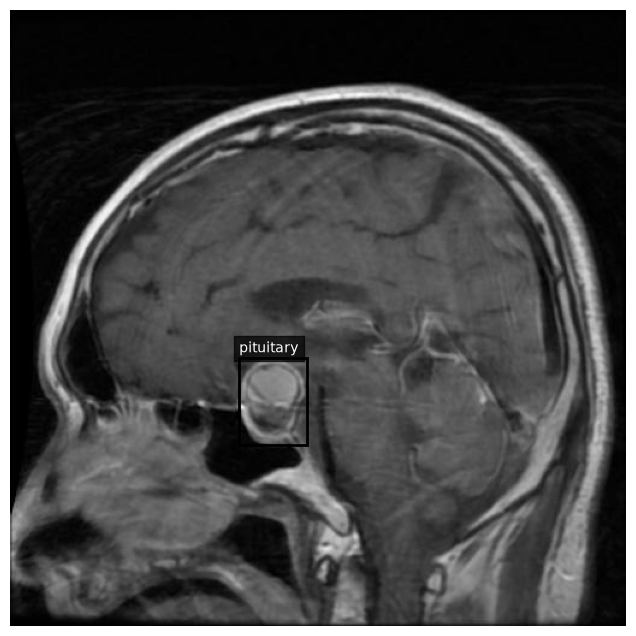

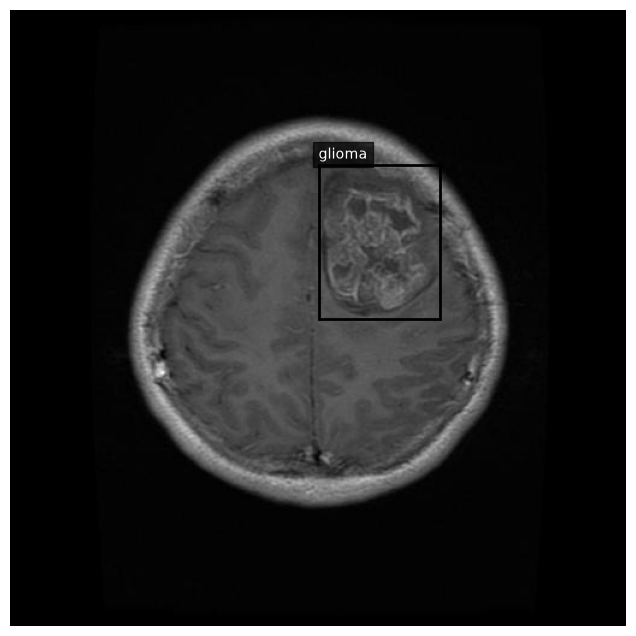

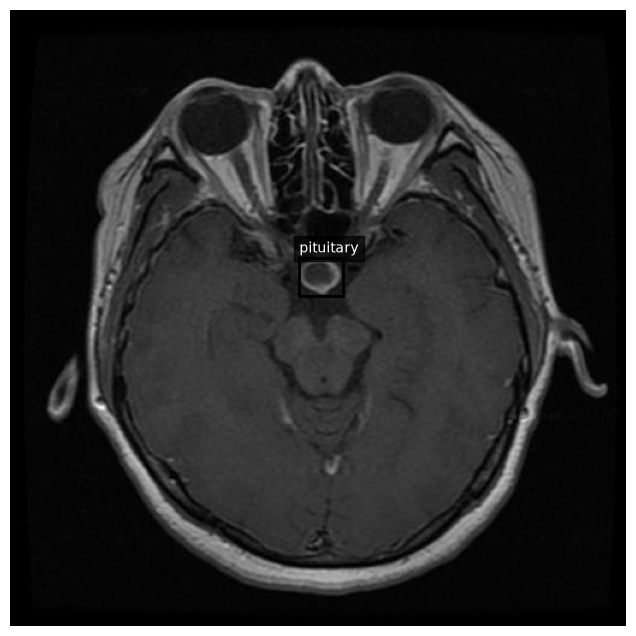

In [29]:
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
def show_yolo_annotation(image_path, label_path, class_names):
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image)
    ax.axis("off")

    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        class_id, x_center, y_center, box_width, box_height = map(
            float, line.split()
        )

        x_center *= width
        y_center *= height
        box_width *= width
        box_height *= height

        x_min = x_center - box_width / 2
        y_min = y_center - box_height / 2

        rect = Rectangle(
            (x_min, y_min),
            box_width,
            box_height,
            fill=False,
            linewidth=2,
        )
        ax.add_patch(rect)

        class_name = class_names[int(class_id)]
        ax.text(
            x_min,
            max(0, y_min - 5),
            class_name,
            color="white",
            bbox={"facecolor": "black", "alpha": 0.7},
        )

    plt.show()

CLASS_NAMES = [
    "glioma",      # 0
    "meningioma",  # 1
    "notumor",     # 2
    "pituitary",   # 3
]
train_images_dir = YOLO_IMAGES_DIR / "train"
train_labels_dir = YOLO_LABELS_DIR / "train"

example_images = [
    p for p in train_images_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
]

if not example_images:
    raise ValueError("No training images are available to visualize.")

for image_path in example_images[:3]:
    label_path = (
        train_labels_dir
        / image_path.relative_to(train_images_dir).with_suffix(".txt")
    )
    show_yolo_annotation(image_path, label_path, CLASS_NAMES)

In [30]:
from pathlib import Path
from collections import Counter, defaultdict
import yaml

# ============================================================
# 1. CONFIGURATION
# ============================================================

YOLO_SOURCE_DIR = PROJECT_ROOT / "data" / "yolo"
YOLO_DATA_DIR = PROJECT_ROOT / "data" / "yolo_prepared"

data_yaml_path = YOLO_DATA_DIR / "data.yaml"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ============================================================
# 2. VERIFY DATASET STRUCTURE
# ============================================================

for split in ["train", "val"]:
    for kind in ["images", "labels"]:
        folder = YOLO_DATA_DIR / kind / split

        if not folder.is_dir():
            raise FileNotFoundError(
                f"Missing directory: {folder}"
            )

        if kind == "images":
            files = [
                p for p in folder.rglob("*")
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            ]
        else:
            files = list(folder.rglob("*.txt"))

        print(f"{kind}/{split}: {len(files)} files")

        if not files:
            raise ValueError(f"No files found in {folder}")

# ============================================================
# 3. COUNT ANNOTATION CLASS IDS
# ============================================================

counts = Counter()

for label_path in (YOLO_DATA_DIR / "labels").rglob("*.txt"):
    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        parts = line.split()

        if len(parts) != 5:
            raise ValueError(
                f"Invalid YOLO annotation: {label_path}"
            )

        class_id = int(parts[0])
        counts[class_id] += 1

print("\nClass IDs:", dict(sorted(counts.items())))

# ============================================================
# 4. IDENTIFY CLASS NAMES FROM SOURCE FOLDERS
# ============================================================

from collections import Counter, defaultdict
import pandas as pd

YOLO_SOURCE_DIR = PROJECT_ROOT / "data" / "yolo"

folder_counts = defaultdict(Counter)
examples = defaultdict(list)

for split in ["Train", "Val"]:
    split_dir = YOLO_SOURCE_DIR / split

    if not split_dir.exists():
        continue

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        labels_dir = class_dir / "labels"

        if not labels_dir.exists():
            continue

        for label_path in labels_dir.rglob("*.txt"):
            for line in label_path.read_text().splitlines():
                if not line.strip():
                    continue

                class_id = int(line.split()[0])

                folder_counts[class_dir.name][class_id] += 1

                key = (class_dir.name, class_id)

                if len(examples[key]) < 3:
                    examples[key].append(str(label_path))

# Display class ID distribution
df = pd.DataFrame.from_dict(
    folder_counts,
    orient="index"
).fillna(0).astype(int)

df = df.reindex(sorted(df.columns), axis=1)
df.columns = [f"Class {c}" for c in df.columns]

print("Class ID distribution by source folder:")
display(df)

print("\nExample annotation files:")

for (folder, class_id), paths in examples.items():
    print(f"\n{folder} — Class {class_id}")
    for path in paths:
        print(" ", path)

# Derive the class mapping from the dominant class ID in each
# source folder. Individual files may contain extra boxes with a
# different class ID, so a strict one-ID-per-folder check is not
# reliable here.
class_mapping = {}

for folder_name, class_counts in folder_counts.items():
    if not class_counts:
        continue

    class_id, _ = class_counts.most_common(1)[0]
    normalized_name = (
        folder_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    if (
        class_id in class_mapping
        and class_mapping[class_id] != normalized_name
    ):
        raise ValueError(
            f"Class ID {class_id} maps to multiple folder names: "
            f"{class_mapping[class_id]!r} and {normalized_name!r}"
        )

    class_mapping[class_id] = normalized_name

# ============================================================
# 5. VALIDATE CLASS MAPPING
# ============================================================

annotation_ids = set(counts.keys())
mapped_ids = set(class_mapping.keys())

if annotation_ids != mapped_ids:
    raise ValueError(
        f"Annotation IDs {annotation_ids} do not match "
        f"mapped IDs {mapped_ids}"
    )

expected_ids = set(range(len(class_mapping)))

if mapped_ids != expected_ids:
    raise ValueError(
        f"YOLO class IDs must be consecutive from 0. "
        f"Found: {sorted(mapped_ids)}"
    )

CLASS_NAMES = dict(sorted(class_mapping.items()))

print("\nDetected class mapping:")
for class_id, class_name in CLASS_NAMES.items():
    print(f"{class_id}: {class_name}")

# ============================================================
# 6. CREATE DATA.YAML
# ============================================================

config = {
    "path": str(YOLO_DATA_DIR.resolve()),
    "train": "images/train",
    "val": "images/val",
    "names": CLASS_NAMES,
}

with open(data_yaml_path, "w") as f:
    yaml.safe_dump(
        config,
        f,
        sort_keys=False,
        allow_unicode=True
    )

# ============================================================
# 7. VERIFY YAML
# ============================================================

print("\nYOLO configuration created:")
print(data_yaml_path)

print("\n--- data.yaml ---")
print(data_yaml_path.read_text())

print("\nDataset configuration completed.")

images/train: 4737 files
labels/train: 4737 files
images/val: 149 files
labels/val: 149 files

Class IDs: {0: 1349, 1: 1624, 2: 720, 3: 1781}
Class ID distribution by source folder:


,Class 0,Class 1,Class 2,Class 3
Glioma,1500,3,0,164
Meningioma,2,1620,0,109
No Tumor,0,0,811,0
Pituitary,0,1,0,1663



Example annotation files:

Glioma — Class 0
  /home/moali/projects/brainscan_ai/data/yolo/Train/Glioma/labels/Tr-gl_0944.txt
  /home/moali/projects/brainscan_ai/data/yolo/Train/Glioma/labels/gg (720).txt
  /home/moali/projects/brainscan_ai/data/yolo/Train/Glioma/labels/Tr-gl_0982.txt

Glioma — Class 3
  /home/moali/projects/brainscan_ai/data/yolo/Train/Glioma/labels/gg (720).txt
  /home/moali/projects/brainscan_ai/data/yolo/Train/Glioma/labels/Tr-gl_0121.txt
  /home/moali/projects/brainscan_ai/data/yolo/Train/Glioma/labels/gg (327).txt

Glioma — Class 1
  /home/moali/projects/brainscan_ai/data/yolo/Train/Glioma/labels/Tr-gl_1167.txt
  /home/moali/projects/brainscan_ai/data/yolo/Train/Glioma/labels/Te-gl_0041.txt
  /home/moali/projects/brainscan_ai/data/yolo/Train/Glioma/labels/Te-gl_0043.txt

Meningioma — Class 1
  /home/moali/projects/brainscan_ai/data/yolo/Train/Meningioma/labels/Tr-me_1064.txt
  /home/moali/projects/brainscan_ai/data/yolo/Train/Meningioma/labels/Tr-me_0908.txt
  /h

### 11 — Initialize YOLOv8 and train the detector

In [31]:
import torch
import shutil
from ultralytics import YOLO

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Pretrained YOLOv8 weights; downloads them if not already available.
model = YOLO("yolov8n.pt")

EPOCHS = 50
IMAGE_SIZE = 64 
BATCH_SIZE = 16
PATIENCE = 10
YOLO_DATA_DIR = PROJECT_ROOT / "data" / "yolo_prepared"
data_yaml_path = YOLO_DATA_DIR / "data.yaml"

train_results = model.train(
    data=str(data_yaml_path),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    patience=PATIENCE,
    seed=RANDOM_STATE,
    project=str(YOLO_RUNS_DIR),
    name="brainscan_yolov8",
    exist_ok=True,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=4,
    plots=True,
    save=True,
)

print("Training completed.")


PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation Laptop GPU
New https://pypi.org/project/ultralytics/8.4.195 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.188 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 7810MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/moali/projects/brainscan_ai/data/yolo_prepared/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv

Exception in thread Thread-28 (_pin_memory_loop):
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1073, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1010, in run
    self._target(*self._args, **self._kwargs)
  File "/home/moali/projects/brainscan_ai/.venv/lib/python3.12/site-packages/torch/utils/data/_utils/pin_memory.py", line 52, in _pin_memory_loop
    do_one_step()
  File "/home/moali/projects/brainscan_ai/.venv/lib/python3.12/site-packages/torch/utils/data/_utils/pin_memory.py", line 28, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/queues.py", line 122, in get
    return _ForkingPickler.loads(res)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/moali/projects/brainscan_ai/.venv/lib/python3.12/site-packages/torch/multiprocessing/reductions.py", line 538, in rebuild_storage_fd
    fd =

KeyboardInterrupt: 

### 12 — Save the trained model

In [ ]:
best_weights = (
    YOLO_RUNS_DIR
    / "brainscan_yolov8"
    / "weights"
    / "best.pt"
)

last_weights = (
    YOLO_RUNS_DIR
    / "brainscan_yolov8"
    / "weights"
    / "last.pt"
)

if not best_weights.is_file():
    raise FileNotFoundError(
        f"Best model weights were not found: {best_weights}"
    )

saved_model_path = DETECTION_MODELS_DIR / "brainscan_yolov8_best.pt"

shutil.copy2(best_weights, saved_model_path)

print(f"Best model saved to: {saved_model_path}")

if last_weights.is_file():
    print(f"Last checkpoint: {last_weights}")

### 13 — Evaluate on the test split

In [ ]:
best_model = YOLO(str(saved_model_path))

test_metrics = best_model.val(
    data=str(data_yaml_path),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=0 if torch.cuda.is_available() else "cpu",
    project=str(YOLO_RUNS_DIR),
    name="brainscan_yolov8_test",
    plots=True,
)

metrics_summary = {
    "model": str(saved_model_path),
    "test_map50": float(test_metrics.box.map50),
    "test_map50_95": float(test_metrics.box.map),
    "test_precision": float(test_metrics.box.mp),
    "test_recall": float(test_metrics.box.mr),
}

display(pd.DataFrame([metrics_summary]))

metrics_path = REPORTS_DIR / "object_detection_metrics.json"
metrics_path.write_text(json.dumps(metrics_summary, indent=2))

print(f"Metrics saved to: {metrics_path}")

### 14 — Predict and visualize a test image

In [ ]:
test_images_dir = YOLO_IMAGES_DIR / "test"

test_images = [
    p for p in test_images_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
]

if not test_images:
    raise ValueError("No test images found.")

sample_image = test_images[0]

predictions = best_model.predict(
    source=str(sample_image),
    imgsz=IMAGE_SIZE,
    conf=0.25,
    device=0 if torch.cuda.is_available() else "cpu",
    save=False,
    verbose=False,
)

annotated_image = predictions[0].plot()

plt.figure(figsize=(10, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.title(f"YOLOv8 predictions: {sample_image.name}")
plt.show()

### 15 — Save a prediction report

In [ ]:
prediction = predictions[0]

boxes = prediction.boxes
prediction_rows = []

if boxes is not None and len(boxes) > 0:
    coordinates = boxes.xyxy.cpu().numpy()
    confidences = boxes.conf.cpu().numpy()
    class_ids = boxes.cls.cpu().numpy().astype(int)

    for xyxy, confidence, class_id in zip(
        coordinates, confidences, class_ids
    ):
        prediction_rows.append({
            "image": sample_image.name,
            "class_id": int(class_id),
            "class_name": CLASS_NAMES[class_id],
            "confidence": float(confidence),
            "x_min": float(xyxy[0]),
            "y_min": float(xyxy[1]),
            "x_max": float(xyxy[2]),
            "y_max": float(xyxy[3]),
        })

prediction_df = pd.DataFrame(
    prediction_rows,
    columns=[
        "image", "class_id", "class_name", "confidence",
        "x_min", "y_min", "x_max", "y_max",
    ],
)

prediction_report_path = REPORTS_DIR / "sample_detection_predictions.csv"
prediction_df.to_csv(prediction_report_path, index=False)

print(f"Image: {sample_image}")
print(f"Detections: {len(prediction_df)}")
print(f"Report saved: {prediction_report_path}")

display(prediction_df)

### 16 — Summarize the experiment artifacts

In [ ]:
artifacts = {
    "project_root": str(PROJECT_ROOT),
    "dataset_yaml": str(data_yaml_path),
    "trained_model": str(saved_model_path),
    "metrics_report": str(metrics_path),
    "prediction_report": str(prediction_report_path),
    "training_run_directory": str(
        YOLO_RUNS_DIR / "brainscan_yolov8"
    ),
}

for name, path in artifacts.items():
    print(f"{name}: {path}")

artifact_summary_path = REPORTS_DIR / "object_detection_artifacts.json"
artifact_summary_path.write_text(json.dumps(artifacts, indent=2))

print("\nObject-detection experiment summary saved.")